In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Customer Shopping Analysis")
print("Data Analysis Environment Ready!")

Customer Shopping Analysis
Data Analysis Environment Ready!


In [3]:
import pandas as pd

df = pd.read_csv("../data/raw/customer_shopping_behavior.csv")

df.head()


FileNotFoundError: [Errno 2] No such file or directory: '../data/raw/customer_shopping_behavior.csv'

In [4]:
import os

print(os.getcwd())
print(os.listdir("../data/raw"))


c:\Users\Himaya\Downloads\DataAnalystPortfolio\CustomerShoppingAnalysis\notebooks
['Customer Purchase Behavior']


In [5]:
import os

print(os.listdir("../data/raw/Customer Purchase Behavior"))


['shopping_trends.csv']


In [6]:
import pandas as pd

df = pd.read_csv("../data/raw/Customer Purchase Behavior/shopping_trends.csv")

df.head()


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [7]:
print("Rows and Columns:", df.shape)


Rows and Columns: (3900, 19)


In [8]:
df.columns

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Payment Method',
       'Shipping Type', 'Discount Applied', 'Promo Code Used',
       'Previous Purchases', 'Preferred Payment Method',
       'Frequency of Purchases'],
      dtype='str')

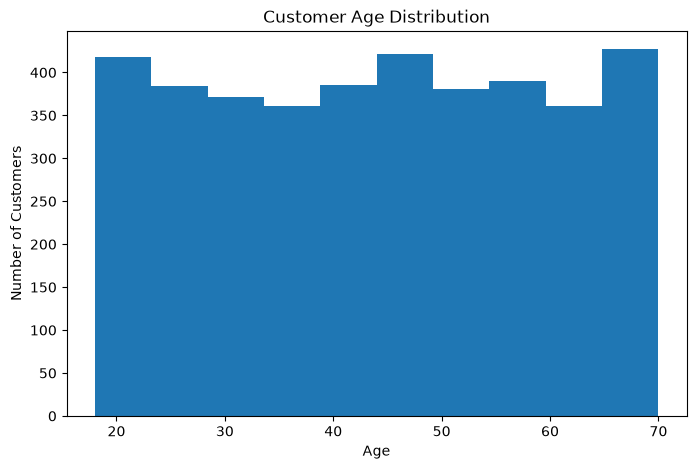

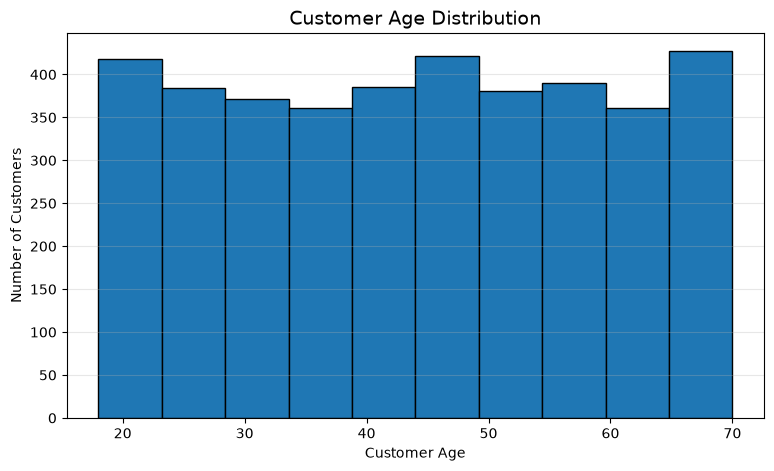

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df['Age'], bins=10)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()
category_counts = df['Category'].value_counts()

print(category_counts)



In [14]:
category_counts = df['Category'].value_counts()

print(category_counts)

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64


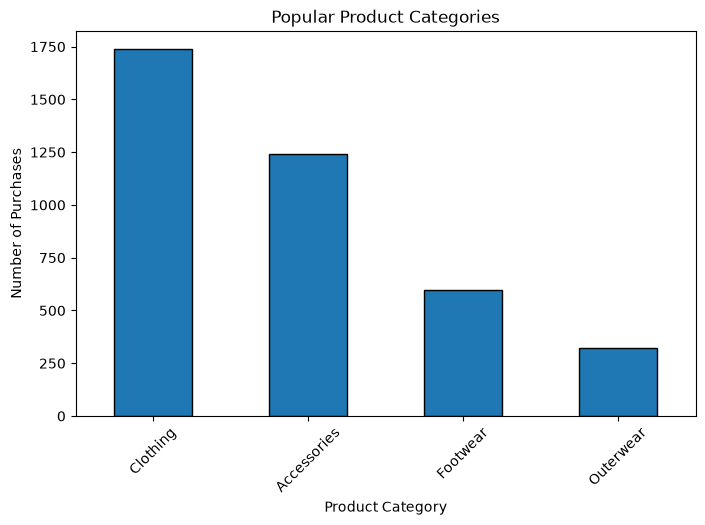

In [15]:
category_counts.plot(
    kind='bar',
    figsize=(8,5),
    edgecolor='black'
)

plt.title('Popular Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)

plt.show()


In [16]:
category_revenue = df.groupby('Category')['Purchase Amount (USD)'].sum()

category_revenue = category_revenue.sort_values(ascending=False)

print(category_revenue)

Category
Clothing       104264
Accessories     74200
Footwear        36093
Outerwear       18524
Name: Purchase Amount (USD), dtype: int64


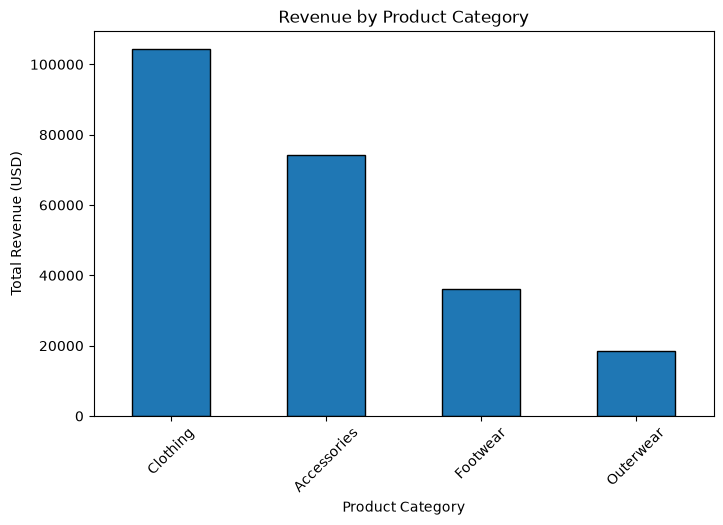

In [17]:
category_revenue.plot(
    kind='bar',
    figsize=(8,5),
    edgecolor='black'
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue (USD)')
plt.xticks(rotation=45)

plt.show()

In [9]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   str    
 3   Item Purchased            3900 non-null   str    
 4   Category                  3900 non-null   str    
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   str    
 7   Size                      3900 non-null   str    
 8   Color                     3900 non-null   str    
 9   Season                    3900 non-null   str    
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   str    
 12  Payment Method            3900 non-null   str    
 13  Shipping Type             3900 non-null   str    
 14  Discount Applied   

In [10]:
df.isnull().sum()


Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

In [11]:
df.describe()


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [18]:
gender_spending = df.groupby('Gender')['Purchase Amount (USD)'].sum()

print(gender_spending)

Gender
Female     75191
Male      157890
Name: Purchase Amount (USD), dtype: int64


In [19]:
gender_analysis = df.groupby('Gender')['Purchase Amount (USD)'].agg(
    ['count', 'sum', 'mean']
)

print(gender_analysis)

        count     sum       mean
Gender                          
Female   1248   75191  60.249199
Male     2652  157890  59.536199


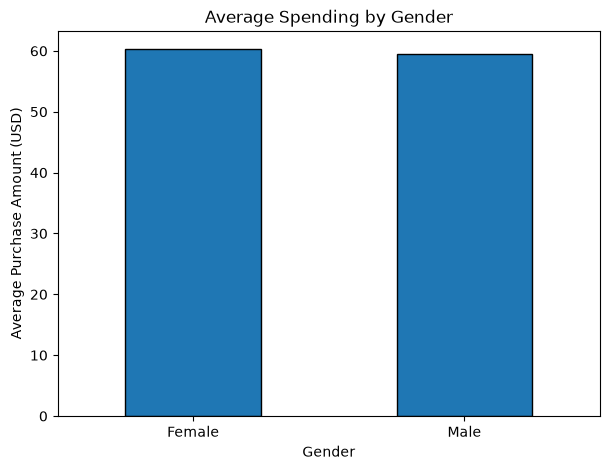

In [20]:
gender_analysis['mean'].plot(
    kind='bar',
    figsize=(7,5),
    edgecolor='black'
)

plt.title('Average Spending by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Purchase Amount (USD)')
plt.xticks(rotation=0)

plt.show()

In [21]:
season_revenue = df.groupby('Season')['Purchase Amount (USD)'].sum()

season_revenue = season_revenue.sort_values(ascending=False)

print(season_revenue)

Season
Fall      60018
Spring    58679
Winter    58607
Summer    55777
Name: Purchase Amount (USD), dtype: int64


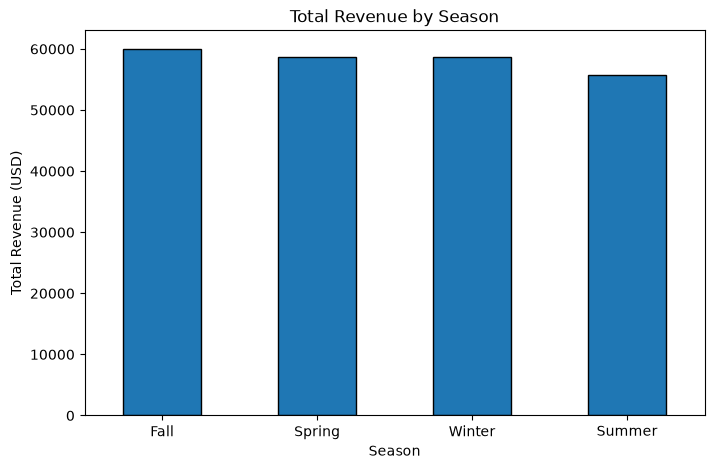

In [22]:
season_revenue.plot(
    kind='bar',
    figsize=(8,5),
    edgecolor='black'
)

plt.title('Total Revenue by Season')
plt.xlabel('Season')
plt.ylabel('Total Revenue (USD)')
plt.xticks(rotation=0)

plt.show()

In [23]:
payment_counts = df['Payment Method'].value_counts()

print(payment_counts)

Payment Method
Credit Card      696
Venmo            653
Cash             648
PayPal           638
Debit Card       633
Bank Transfer    632
Name: count, dtype: int64


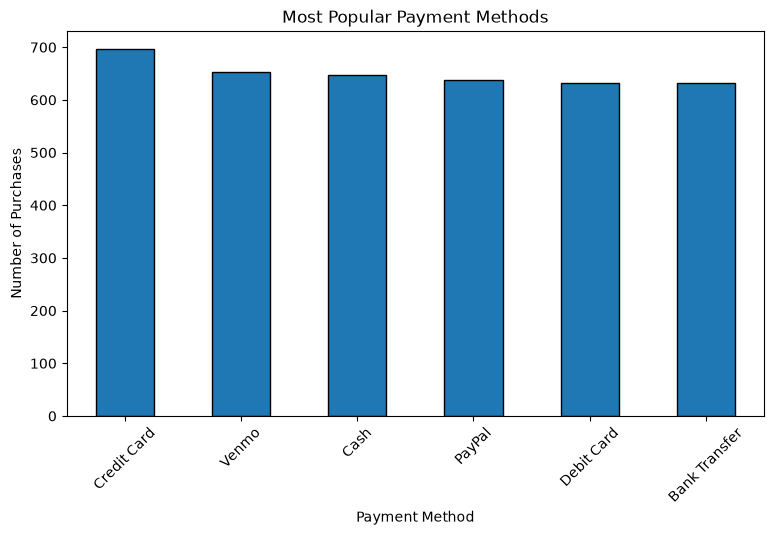

In [24]:
payment_counts.plot(
    kind='bar',
    figsize=(9,5),
    edgecolor='black'
)

plt.title('Most Popular Payment Methods')
plt.xlabel('Payment Method')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)

plt.show()

In [25]:
subscription_analysis = df.groupby('Subscription Status')['Purchase Amount (USD)'].agg(
    ['count', 'sum', 'mean']
)

print(subscription_analysis)

                     count     sum       mean
Subscription Status                          
No                    2847  170436  59.865121
Yes                   1053   62645  59.491928


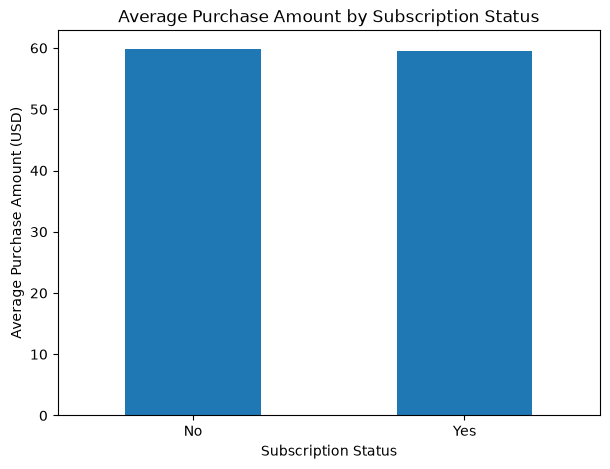

In [26]:
subscription_analysis['mean'].plot(
    kind='bar',
    figsize=(7, 5),
    title='Average Purchase Amount by Subscription Status',
    xlabel='Subscription Status',
    ylabel='Average Purchase Amount (USD)'
)

plt.xticks(rotation=0)
plt.show()

## Key Business Insights

1. **Product Category:** Clothing is the highest revenue-generating category, contributing $104,264.

2. **Gender Analysis:** Male customers generate higher total revenue due to their larger customer count. However, female customers have a slightly higher average purchase amount.

3. **Seasonal Analysis:** Fall generates the highest revenue ($60,018), while Summer generates the lowest revenue ($55,777).

4. **Payment Method:** Credit Card is the most frequently used payment method, with 696 transactions.

5. **Subscription Analysis:** Non-subscribed customers generate higher total revenue. However, the average spending of subscribers and non-subscribers is almost similar.

## Conclusion

The analysis identifies Clothing as the leading product category and Fall as the highest revenue-generating season. Customer purchasing behaviour varies across gender, payment methods, and subscription status. These insights can help the business improve inventory planning, marketing strategies, and customer engagement.

In [27]:
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Pandas Version: 3.1.1
NumPy Version: 2.5.4
